# N5 · El prior y la degradación, en hexbins

Complemento de N3 (secciones 2–4): en vez de un predictor del prior a la vez, dos a la vez. Un **experimento** es el de N3: la asimilación de una observación de $Z$, evaluada en la celda observada, para un (dataset, hora, miembro verdad, celda) y un esquema. Los errores son los de N3: $e = \overline{\phi} - \phi_\mathrm{true}$ en el prior ($f$) y en el posterior ($a$), con $h(\mathbf{x}_\mathrm{true})$ sin ruido como verdad de $Z$.

Los ejes de cada figura son dos métricas del prior en la celda observada. Cada hexbin junta los experimentos que caen en él y se colorea con

- $\mathrm{SS}_\mathrm{RMSE} = 1 - \sqrt{\sum e_a^2 / \sum e_f^2}$ sobre los experimentos del hexbin: la definición de N3 sobre la población del hexbin, no el promedio del SS de cada punto, que no tiene cota inferior cuando $|e_f| \to 0$;
- la probabilidad de degradación $P_\mathrm{deg} = 1 - F$ entre los experimentos del hexbin que cambian ($\big||e_f| - |e_a|\big|$ mayor que la tolerancia de la variable, la de N3).

El error es el de la **variable evaluada** ($Z$ o $w$), que no tiene por qué ser la de los ejes. Cada figura tiene tres filas (TEnKF-T1, T2 y T3) y dos columnas ($\mathrm{SS}_\mathrm{RMSE}$ y $P_\mathrm{deg}$). Por pareja de ejes y variable evaluada hay cuatro figuras: A, B, C y los tres juntos; en el agrupado, C aporta cerca del 70 % de los experimentos. Las cuatro horas y los 60 miembros verdad van juntos, y entran todos los experimentos, sin regla de rechazo.

| código | métrica del prior en la celda observada |
|---|---|
| `Z_obs` | la observación asimilada $y^o$ (con ruido) |
| `Z_mean` | la media del ensamble de $H(\mathbf{x}^f)$ |
| `Z_spread` | la dispersión de $H(\mathbf{x}^f)$ (desviación estándar, ddof = 1) |
| `d` | la innovación $d = y^o - \overline{H(\mathbf{x}^f)}$ |
| `d_norm` | $d/\sqrt{\sigma_f^2 + R}$, con signo |
| `d_abs` | $\lvert d \rvert$ |
| `Z_skew`, `Z_kurt` | la asimetría y el exceso de curtosis de $H(\mathbf{x}^f)$ (Nerger 2022, ec. 25 y 26) |
| `w_mean`, `w_spread`, `w_skew`, `w_kurt` | lo mismo para $w^f$ |
| `w_skew_abs` | $\lvert$asimetría$\rvert$ de $w^f$: con $Z$ evaluado la respuesta depende casi solo del tamaño de la asimetría, no del signo |

Los ejes van de los percentiles 0,5 a 99,5 de la población agrupada, los mismos en las cuatro figuras de una pareja; los experimentos fuera de los ejes no entran. Un hexbin se colorea si tiene al menos `N_MIN_HEX` experimentos (para $P_\mathrm{deg}$, experimentos que cambian); los demás quedan en el gris del fondo.

Las figuras van a `figures/<idioma>/N5/<variable evaluada>/<dataset>/<x>__<y>.png`, con dataset ∈ {A, B, C, pooled}; por defecto solo en inglés (`SAVE_LANGS`). Para cambiar las parejas se edita `PAIRS` (sección 3). Para poner otras variables de estado en los ejes o evaluarlas se editan `AXIS_VARS` y `SCORED` (sección 0); si el intermedio no las tiene, se rehace solo. La sección 4 mira las observaciones débiles, donde T2 y T3 degradan $w$; la 5 compara la regla $d \in [0, 10]$ con la misma regla limitada a $y^o < 10$; la 6 cruza la innovación con los miembros del prior con eco, $N_{Z>0}$, que ninguna pareja de hexbins muestra.

In [1]:
import contextlib
import io
import itertools
import time
import zipfile
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize

import nbcommon as nb

REBUILD = False             # True: rehace los intermedios desde los archivos crudos (~5 min)
SAVE_LANGS = ("en",)        # los idiomas que se guardan; ("es", "en") para los dos
SHOW = "en"                 # el idioma que se muestra en línea

# Un hexbin se colorea si tiene al menos N_MIN_HEX experimentos (para P_deg, que cambian).
N_MIN_HEX = 1
GRID_NX = 40                # hexágonos a lo ancho de un panel
Q_LIM = (0.5, 99.5)         # percentiles de la población agrupada que fijan los ejes

nb.set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

In [2]:
# Etiquetas propias de este notebook; el vocabulario común está en nb.VOCAB. Las de las
# métricas de las variables de estado se arman con plantillas, para cualquier AXIS_VARS.
SYM = {"obs": "Z", "qg": "q_g", "qr": "q_r", "qs": "q_s", "T": "T", "P": "P",
       "u": "u", "v": "v", "w": "w", "qtot": "q_g+q_r+q_s"}
UNIT = {"qg": "kg kg$^{-1}$", "qr": "kg kg$^{-1}$", "qs": "kg kg$^{-1}$", "T": "K", "P": "Pa",
        "u": "m s$^{-1}$", "v": "m s$^{-1}$", "w": "m s$^{-1}$"}
HXF = r"H(\mathbf{x}^f)"
STATE_STATS = ("mean", "spread", "skew", "kurt")             # las que están en los archivos
STATE_METRICS = ("mean", "spread", "skew", "skew_abs", "kurt")  # skew_abs se calcula al cargar
TEMPLATES = {
    "es": {"mean": r"media del ensamble $\overline{{{s}^f}}$ [{u}]", "spread": r"dispersión de ${s}^f$ [{u}]",
           "skew": r"asimetría de ${s}^f$", "skew_abs": r"|asimetría| de ${s}^f$",
           "kurt": r"exceso de curtosis de ${s}^f$"},
    "en": {"mean": r"ensemble mean $\overline{{{s}^f}}$ [{u}]", "spread": r"spread of ${s}^f$ [{u}]",
           "skew": r"skewness of ${s}^f$", "skew_abs": r"|skewness| of ${s}^f$",
           "kurt": r"excess kurtosis of ${s}^f$"},
}
LABELS = {
    "es": {
        "Z_obs": r"observación $y^o$ [dBZ]",
        "Z_mean": rf"media del ensamble $\overline{{{HXF}}}$ [dBZ]",
        "Z_spread": rf"dispersión de ${HXF}$ [dBZ]",
        "d": nb.VOCAB["es"]["innov"],
        "d_norm": r"innovación normalizada $d/\sqrt{\sigma_f^2+R}$",
        "d_abs": r"$|d|$ [dBZ]",
        "Z_skew": rf"asimetría de ${HXF}$",
        "Z_kurt": rf"exceso de curtosis de ${HXF}$",
        "scored": "evaluado en",
        "pooled": "los tres datasets",
        "Z_nact": r"miembros con eco $N_{Z>0}$",
        "count": "experimentos",
    },
    "en": {
        "Z_obs": r"observation $y^o$ [dBZ]",
        "Z_mean": rf"ensemble mean $\overline{{{HXF}}}$ [dBZ]",
        "Z_spread": rf"spread of ${HXF}$ [dBZ]",
        "d": nb.VOCAB["en"]["innov"],
        "d_norm": r"normalized innovation $d/\sqrt{\sigma_f^2+R}$",
        "d_abs": r"$|d|$ [dBZ]",
        "Z_skew": rf"skewness of ${HXF}$",
        "Z_kurt": rf"excess kurtosis of ${HXF}$",
        "scored": "scored on",
        "pooled": "all three datasets",
        "Z_nact": r"members with echo $N_{Z>0}$",
        "count": "experiments",
    },
}
for _l in nb.LANGS:
    for _v in nb.VARS:
        for _s in STATE_METRICS:
            LABELS[_l][f"{_v}_{_s}"] = TEMPLATES[_l][_s].format(s=SYM[_v], u=UNIT[_v])
assert set(LABELS["es"]) == set(LABELS["en"])

DSL = nb.DS_LABEL

## 0 · Postprocesado

Lee los 720 archivos del barrido (A, B, C × 4 horas × 60 miembros verdad) y escribe un intermedio por dataset, `data/derived/N5/N5_points_{A,B,C}.npz`, con una fila por experimento (celda × hora × miembro verdad):

- las métricas del prior: las ocho de $Z$ y, para cada variable de `AXIS_VARS`, media, dispersión, asimetría y exceso de curtosis (float32, como en los archivos);
- para cada variable de `SCORED`, $|e_f|$ y $|e_a|$ de TEnKF-T1, T2 y T3, con las mismas cuentas que N3 (float64);
- $h(\mathbf{x}_\mathrm{true})$ sin ruido (`Z_true`), solo para el diagnóstico de la sección 4: no es una métrica del prior;
- los miembros del prior con $Z > 0$ en la celda (`Z_nact`, el `n_active_f_point` del runner), para la sección 6: es discreto, así que no entra en las parejas de hexbins;
- la hora y el miembro verdad.

`|asimetría|` no se guarda: se calcula al cargar.

El prior no depende del esquema: se comprueba en cada archivo. Después las sumas de N3 ($n$, $\sum e_f^2$, $\sum e_a^2$, $n_\mathrm{change}$, $n_\mathrm{imp}$) se rehacen desde los puntos, por (dataset, hora, miembro verdad, esquema, variable), y se comparan con `N3_sums_base.csv`.

In [3]:
OUT = nb.DERIVED / "N5"

DATASETS = ("A", "B", "C")
HOURS = ("18", "19", "20", "21")
TMS = tuple(range(60))
LOC = 0.1
NT = (1, 2, 3)                               # TEnKF-T1, T2 y T3: las filas de cada figura

AXIS_VARS = ("w",)                           # variables de estado con métricas en los ejes
SCORED = ("obs", "w")                        # variables evaluadas: obs = Z, las de nb.VARS o qtot
STATE = tuple(nb.VARS)
HYDRO = ("qg", "qr", "qs")
assert set(AXIS_VARS) <= set(STATE) and set(SCORED) <= {"obs", "qtot", *STATE}
# Banda de empate de cada variable, la de N3; qtot lleva la de los hidrometeoros.
TOLS = {"obs": nb.TOL["obs"], **{v: nb.TOL[v] for v in STATE}, "qtot": 1e-7}

Z_METRICS = ("Z_obs", "Z_mean", "Z_spread", "d", "d_norm", "d_abs", "Z_skew", "Z_kurt")
STORED = Z_METRICS + tuple(f"{v}_{s}" for v in AXIS_VARS for s in STATE_STATS)
METRICS = Z_METRICS + tuple(f"{v}_{s}" for v in AXIS_VARS for s in STATE_METRICS)
FORMAT = 3                                   # 2: con Z_true; 3: con Z_nact
SIGNED = {"d", "d_norm", "Z_skew", "Z_kurt"} | {f"{v}_{s}" for v in STATE for s in ("mean", "skew", "kurt")}
FILES = {ds: OUT / f"N5_points_{ds}.npz" for ds in DATASETS}

# Columnas del archivo que forman el prior (no dependen del esquema) y del posterior.
_err_vars = sorted({v for v in SCORED if v in STATE} | (set(HYDRO) if "qtot" in SCORED else set()))
PRIOR_KEYS = (["yo", "yo_clean", "dep_b", "hxf_mean_obs", "spread_f_point_obs", "skew_f_point_obs",
               "kurt_f_point_obs", "rmse_f_point_obs", "n_active_f_point"]
              + [f"{p}_point_{v}" for v in AXIS_VARS for p in ("mean_f", "spread_f", "skew_f", "kurt_f")]
              + [f"{p}_point_{v}" for v in _err_vars for p in ("mean_f", "truth")])
PRIOR_KEYS = list(dict.fromkeys(PRIOR_KEYS))
POST_KEYS = ["rmse_a_point_obs"] + [f"mean_a_point_{v}" for v in _err_vars]
KEYS = ["i", "j", "k", "method", "ntemp"] + PRIOR_KEYS + POST_KEYS


def run_of(ds, hour):
    return f"WS_{ds}_sweep_{hour}00_LOC{LOC}_ALLMEM"


def lab(n):
    return f"TEnKF-T{int(n)}"


def run_R():
    """R de las 12 corridas, que tiene que ser uno solo; y cada corrida, del dataset de su tag."""
    Rs = set()
    for ds in DATASETS:
        for hh in HOURS:
            tag = run_of(ds, hh)
            cfg = nb.run_config(tag)
            did_used = nb.dataset_of(cfg["paths"]["prepared"])
            did_want = nb.dataset_of(nb.subset_path(hh, ds))
            if did_used is not None and did_want is not None:
                assert did_used == did_want, f"{tag} se corrió sobre el dataset {did_used}"
            Rs.add(float(cfg["obs"]["obs_error_var"]))
    assert len(Rs) == 1, f"R distinto entre corridas: {Rs}"
    return Rs.pop()


def read_file(f, R):
    """Un archivo del barrido -> métricas del prior y |e| de las variables evaluadas.

    Las filas de cada esquema se ordenan por celda, como en N3; los tres esquemas tienen
    que compartir celdas y prior. |e| de Z es rmse_*_point_obs; el de una variable de
    estado, |media − verdad| en float64; el de qtot, |suma de los errores con signo|.
    """
    with np.load(f) as z:
        A = {k: z[k] for k in KEYS}
    meth, nt = A["method"].astype(str), A["ntemp"].astype(int)
    dims = tuple(int(A[c].max()) + 1 for c in ("i", "j", "k"))
    key = np.ravel_multi_index((A["i"], A["j"], A["k"]), dims)
    rows = {}
    for n in NT:
        r = np.flatnonzero((meth == "TEnKF") & (nt == n))
        rows[n] = r[np.argsort(key[r], kind="stable")]
    ref = rows[NT[0]]
    assert ref.size and np.unique(key[ref]).size == ref.size, f"{f}: celdas repetidas"
    for n, r in rows.items():
        assert np.array_equal(key[r], key[ref]), f"{f}: {lab(n)} tiene otras celdas"
        for p in PRIOR_KEYS:
            assert np.array_equal(A[p][r], A[p][ref], equal_nan=True), f"{f}: {p} depende del esquema"
    P = {p: A[p][ref] for p in PRIOR_KEYS}
    # d = yo − media de H(x_f), como la escribe el runner
    assert np.allclose(P["dep_b"], P["yo"] - P["hxf_mean_obs"], rtol=0, atol=1e-4), f"{f}: d ≠ yo − H̄"
    d, sp = P["dep_b"], P["spread_f_point_obs"]
    out = {"Z_obs": P["yo"], "Z_mean": P["hxf_mean_obs"], "Z_spread": sp, "d": d,
           "d_norm": d / np.sqrt(sp ** 2 + R),          # float32, como norm_innov en N3
           "d_abs": np.abs(d), "Z_skew": P["skew_f_point_obs"], "Z_kurt": P["kurt_f_point_obs"]}
    for v in AXIS_VARS:
        for s, p in zip(STATE_STATS, ("mean_f", "spread_f", "skew_f", "kurt_f")):
            out[f"{v}_{s}"] = P[f"{p}_point_{v}"]
    assert set(out) == set(STORED)
    out["Z_true"] = P["yo_clean"]
    out["Z_nact"] = P["n_active_f_point"].astype(np.int16)
    assert (out["Z_nact"] >= 1).all(), f"{f}: observación sin miembros con eco (el filtro de varianza la saca)"

    # errores con signo de las variables de estado, prior y posterior de cada esquema
    e = {}
    for v in _err_vars:
        truth = P[f"truth_point_{v}"].astype(float)
        e[(v, "f")] = P[f"mean_f_point_{v}"].astype(float) - truth
        for n, r in rows.items():
            e[(v, n)] = A[f"mean_a_point_{v}"][r].astype(float) - truth
    for v in SCORED:
        if v == "obs":
            out["ef_obs"] = P["rmse_f_point_obs"].astype(float)
            for n, r in rows.items():
                out[f"ea_obs_T{n}"] = A["rmse_a_point_obs"][r].astype(float)
            continue
        parts = HYDRO if v == "qtot" else (v,)
        out[f"ef_{v}"] = np.abs(sum(e[(q, "f")] for q in parts))
        for n in NT:
            out[f"ea_{v}_T{n}"] = np.abs(sum(e[(q, n)] for q in parts))
    return out


def build():
    R = run_R()
    OUT.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    for ds in DATASETS:
        parts = []
        for hh in HOURS:
            for tm in TMS:
                fs = nb.sweep_files(run_of(ds, hh), [tm])
                assert len(fs) == 1, f"{run_of(ds, hh)} tm{tm:02d}: {len(fs)} archivos"
                p = read_file(fs[0], R)
                p["hour"] = np.full(p["Z_obs"].size, int(hh), np.int8)
                p["tm"] = np.full(p["hour"].size, tm, np.int8)
                parts.append(p)
            print(f"  {DSL[ds]}  {hh} UTC  ({time.time() - t0:.0f} s)", flush=True)
        P = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
        np.savez(FILES[ds], R=np.float64(R), format=np.int64(FORMAT), axis_vars=np.array(AXIS_VARS, str),
                 scored=np.array(SCORED, str), **P)
        del parts, P
    print(f"escrito en {time.time() - t0:.0f} s")


SUMS = ["n", "se2_f", "se2_a", "n_change", "n_imp"]


def sums_by(ef, ea, tol, g, ng):
    """Las sumas de N3 por grupo g (0 … ng−1), sobre los experimentos con error finito."""
    ok = np.isfinite(ef) & np.isfinite(ea)
    gi, ef, ea = g[ok], ef[ok], ea[ok]
    s = ef - ea                                   # > 0: el posterior mejora
    w = (None, ef ** 2, ea ** 2, (np.abs(s) > tol).astype(float), (s > tol).astype(float))
    return np.column_stack([np.bincount(gi, weights=x, minlength=ng)[:ng] for x in w])


def verify(P):
    """Las sumas de N3_sums_base rehechas desde los puntos, por (hora, miembro verdad)."""
    base = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_base.csv", dtype={"hour": str},
                       float_precision="round_trip")
    hours = np.array([int(h) for h in HOURS])
    ng = len(HOURS) * len(TMS)
    for ds in DATASETS:
        Q = P[ds]
        g = np.searchsorted(hours, Q["hour"]) * len(TMS) + Q["tm"]
        assert np.array_equal(hours[g // len(TMS)], Q["hour"]), f"{ds}: horas fuera de {HOURS}"
        for v in SCORED:
            for n in NT:
                mine = sums_by(Q[f"ef_{v}"], Q[f"ea_{v}_T{n}"], TOLS[v], g, ng)
                b = base[(base.dataset == ds) & (base["var"] == v) & (base.method == "TEnKF") & (base.ntemp == n)]
                gb = np.array([HOURS.index(h) * len(TMS) + t for h, t in zip(b.hour, b.tm)])
                ref = b[SUMS].to_numpy(float)[np.argsort(gb)]
                assert np.array_equal(np.sort(gb), np.arange(ng)), f"{ds} {v} {lab(n)}: faltan filas en N3"
                assert np.array_equal(mine[:, [0, 3, 4]], ref[:, [0, 3, 4]]), f"{ds} {v} {lab(n)}: conteos distintos de N3"
                assert np.allclose(mine[:, 1:3], ref[:, 1:3], rtol=1e-12, atol=0), f"{ds} {v} {lab(n)}: Σe² distinta de N3"
    print(f"verificado contra N3_sums_base: {', '.join(SUMS)} por (dataset, hora, miembro verdad), "
          f"variables {', '.join(SCORED)}, {lab(NT[0])}–T{NT[-1]}")

In [4]:
def stale(p):
    """Falta el archivo, no se puede leer (una copia truncada), es de otro formato o no tiene las
    variables de AXIS_VARS y SCORED."""
    if not p.exists():
        return True
    try:
        with np.load(p) as z:
            return ("format" not in z.files or int(z["format"]) != FORMAT
                    or tuple(z["axis_vars"]) != AXIS_VARS or tuple(z["scored"]) != SCORED)
    except (OSError, ValueError, zipfile.BadZipFile) as e:
        print(f"  {p.name} no se puede leer ({type(e).__name__}): se rehace")
        return True


redo = [ds for ds, p in FILES.items() if stale(p)]
if REBUILD or redo:
    print(f"construyendo ({len(redo)} intermedios faltan o no coinciden con AXIS_VARS/SCORED)" if redo else "REBUILD")
    build()
else:
    print(f"intermedios presentes en {nb.REPO.name}/{OUT.relative_to(nb.REPO)}")

P = {}
for ds in DATASETS:
    with np.load(FILES[ds]) as z:
        P[ds] = {k: z[k] for k in z.files if k not in ("R", "format", "axis_vars", "scored")}
        R = float(z["R"])
    for v in AXIS_VARS:
        P[ds][f"{v}_skew_abs"] = np.abs(P[ds][f"{v}_skew"])
verify(P)

n_ds = pd.Series({ds: P[ds]["hour"].size for ds in DATASETS})
print(f"\nR = {R:g} dBZ²")
print(pd.DataFrame({
    "experimentos": n_ds,
    "del agrupado [%]": 100 * n_ds / n_ds.sum(),
    **{f"|e| de {v} no finito [%]": {ds: 100 * np.mean(~(np.isfinite(P[ds][f"ef_{v}"]) & np.isfinite(P[ds][f"ea_{v}_T1"])))
                                     for ds in DATASETS} for v in SCORED},
}).rename(index=DSL).to_string(float_format=lambda v: f"{v:.2f}"))

intermedios presentes en WRF_Single_Cycle_Assimilation/data/derived/N5
verificado contra N3_sums_base: n, se2_f, se2_a, n_change, n_imp por (dataset, hora, miembro verdad), variables obs, w, TEnKF-T1–T3

R = 5 dBZ²
            experimentos  del agrupado [%]  |e| de obs no finito [%]  |e| de w no finito [%]
4 km–5 min       2189088             20.52                      0.00                    0.00
4 km–1 h          942335              8.83                      0.00                    0.01
2 km–5 min       7537603             70.65                      0.00                    0.00


## 1 · Los límites de los ejes

Percentiles `Q_LIM` de cada métrica sobre la población agrupada (A + B + C). "Fuera" es la parte de cada dataset que queda fuera de los límites, valores no finitos incluidos; en una pareja queda fuera a lo sumo la suma de las dos.

In [5]:
LIM, rows = {}, []
for m in METRICS:
    allv = np.concatenate([P[ds][m] for ds in DATASETS]).astype(float)
    lo, hi = (float(x) for x in np.nanpercentile(allv, Q_LIM))
    assert hi > lo, f"{m}: límites degenerados"
    LIM[m] = (lo, hi)
    row = {"métrica": m, "mín": np.nanmin(allv), "lím. inf.": lo, "lím. sup.": hi, "máx": np.nanmax(allv),
           "no finitos [%]": 100 * np.mean(~np.isfinite(allv))}
    for ds in DATASETS:
        x = P[ds][m].astype(float)
        row[f"fuera {DSL[ds]} [%]"] = 100 * np.mean(~((x >= lo) & (x <= hi)))
    rows.append(row)
    del allv
print(pd.DataFrame(rows).set_index("métrica").to_string(float_format=lambda v: f"{v:.4g}"))

                 mín  lím. inf.  lím. sup.   máx  no finitos [%]  fuera 4 km–5 min [%]  fuera 4 km–1 h [%]  fuera 2 km–5 min [%]
métrica                                                                                                                         
Z_obs              0          0      47.36 70.65               0                0.3071              0.1586                0.5987
Z_mean     2.925e-06   0.007113      24.53 48.59               0                0.9073              0.8443                 1.046
Z_spread   2.247e-05    0.05453      18.69 23.09               0                0.6092              0.8524                 1.132
d             -38.32     -13.37      41.37 65.09               0                0.5951              0.2855                 1.207
d_norm        -6.435    -0.9095      6.013  26.2               0                0.9313              0.5941                 1.071
d_abs              0   0.008996      41.37 65.09               0                 0.948           

## 2 · Los hexbins

La grilla es la de `matplotlib.hexbin` (dos redes desplazadas, hexágonos regulares en un panel cuadrado, `GRID_NX` a lo ancho), pero las sumas se hacen con `np.bincount` sobre todos los experimentos, sin submuestrear. A diferencia de `hexbin`, solo entran los experimentos dentro de los ejes. La grilla depende solo de los límites, así que es la misma en las cuatro figuras de una pareja, y las sumas del agrupado son las sumas de A, B y C.

Colores: $\mathrm{SS}_\mathrm{RMSE}$ en `nb.CMAP_SKILL` de −1 a 1 (rojo = mejora; debajo de −1, el color del extremo); $P_\mathrm{deg}$ de 0 a 1 en el mismo mapa invertido, para que en las dos columnas el azul sea degradación. El fondo gris es "sin experimentos" y no se confunde con el blanco de $\mathrm{SS} = 0$ o $P_\mathrm{deg} = 0{,}5$.

In [6]:
def hex_grid(xlim, ylim, nx=GRID_NX):
    """La grilla de matplotlib.hexbin: (nx+1)(ny+1) centros de la red 1 y nx·ny de la red 2."""
    ny = int(nx / np.sqrt(3))
    g = SimpleNamespace(x0=xlim[0], x1=xlim[1], y0=ylim[0], y1=ylim[1], nx=nx, ny=ny,
                        sx=(xlim[1] - xlim[0]) / nx, sy=(ylim[1] - ylim[0]) / ny)
    i1, j1 = np.meshgrid(np.arange(nx + 1), np.arange(ny + 1), indexing="ij")
    i2, j2 = np.meshgrid(np.arange(nx), np.arange(ny), indexing="ij")
    g.cx = np.concatenate([g.x0 + i1.ravel() * g.sx, g.x0 + (i2.ravel() + 0.5) * g.sx])
    g.cy = np.concatenate([g.y0 + j1.ravel() * g.sy, g.y0 + (j2.ravel() + 0.5) * g.sy])
    g.n = g.cx.size
    g.poly = np.array([[.5, -.5], [.5, .5], [0., 1.], [-.5, .5], [-.5, -.5], [0., -1.]]) * [g.sx, g.sy / 3]
    return g


def hex_index(x, y, g):
    """(índice del hexbin de cada experimento, dentro de los ejes): el centro más cercano."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    inside = np.isfinite(x) & np.isfinite(y) & (x >= g.x0) & (x <= g.x1) & (y >= g.y0) & (y <= g.y1)
    ix, iy = (x - g.x0) / g.sx, (y - g.y0) / g.sy
    ix1, iy1 = np.round(ix), np.round(iy)
    ix2, iy2 = np.clip(np.floor(ix), 0, g.nx - 1), np.clip(np.floor(iy), 0, g.ny - 1)
    # distancias en unidades de pantalla: la red 1 tiene sy = √3 sx
    d1 = (ix - ix1) ** 2 + 3.0 * (iy - iy1) ** 2
    d2 = (ix - ix2 - 0.5) ** 2 + 3.0 * (iy - iy2 - 0.5) ** 2
    k = np.where(d1 < d2, ix1 * (g.ny + 1) + iy1, (g.nx + 1) * (g.ny + 1) + ix2 * g.ny + iy2)
    return np.where(inside, k, 0).astype(np.intp), inside


def hex_sums(Q, mx, my, g):
    """Las sumas de N3 por hexbin, {(variable evaluada, Nt): (g.n, len(SUMS))}."""
    k, inside = hex_index(Q[mx], Q[my], g)
    k = k[inside]
    return {(v, n): sums_by(Q[f"ef_{v}"][inside], Q[f"ea_{v}_T{n}"][inside], TOLS[v], k, g.n)
            for v in SCORED for n in NT}


def pair_sums(mx, my):
    """La grilla de la pareja y sus sumas en A, B, C y el agrupado."""
    g = hex_grid(LIM[mx], LIM[my])
    S = {ds: hex_sums(P[ds], mx, my, g) for ds in DATASETS}
    S["pooled"] = {key: sum(S[ds][key] for ds in DATASETS) for key in S[DATASETS[0]]}
    return g, S


def hex_stats(s):
    """SS_RMSE y P_deg por hexbin; NaN donde no llega a N_MIN_HEX o no está definido."""
    n, se2_f, se2_a, n_ch, n_imp = s.T
    with np.errstate(divide="ignore", invalid="ignore"):
        ss = np.where((n >= N_MIN_HEX) & (se2_f > 0), 1 - np.sqrt(se2_a / se2_f), np.nan)
        pdeg = np.where(n_ch >= max(N_MIN_HEX, 1), 1 - n_imp / n_ch, np.nan)
    return ss, pdeg


# Población total con error finito por (dataset, variable evaluada), para el título
N_FIN = {(ds, v): int(np.sum(np.isfinite(P[ds][f"ef_{v}"]) & np.isfinite(P[ds][f"ea_{v}_T{NT[0]}"])))
         for ds in DATASETS for v in SCORED}
for v in SCORED:
    N_FIN[("pooled", v)] = sum(N_FIN[(ds, v)] for ds in DATASETS)

In [7]:
SS_CMAP = plt.get_cmap(nb.CMAP_SKILL)                 # rojo = mejora
PD_CMAP = plt.get_cmap(nb.CMAP_SKILL).reversed()      # invertido: azul = degrada, como el SS negativo
SS_NORM, PD_NORM = Normalize(-1.0, 1.0), Normalize(0.0, 1.0)
BG = "0.80"                                           # sin experimentos


def draw_hexes(ax, g, val, cmap, norm):
    ok = np.isfinite(val)
    verts = np.stack([g.cx[ok], g.cy[ok]], axis=1)[:, None, :] + g.poly[None]
    ax.add_collection(PolyCollection(verts, array=val[ok], cmap=cmap, norm=norm,
                                     edgecolors="face", linewidths=0.15))


def draw_pair(mx, my, v, ds, S, g, lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, axes = plt.subplots(len(NT), 2, sharex=True, sharey=True,
                             figsize=(nb.PAGE_W, nb.PAGE_W * 1.38), constrained_layout=True)
    letters = iter("abcdef")
    for r, n in enumerate(NT):
        ss, pdeg = hex_stats(S[ds][(v, n)])
        for c, (val, cmap, norm, name) in enumerate(((ss, SS_CMAP, SS_NORM, V["ss_rmse"]),
                                                     (pdeg, PD_CMAP, PD_NORM, V["p_deg"]))):
            ax = axes[r, c]
            ax.set_facecolor(BG)
            ax.grid(False)
            draw_hexes(ax, g, val, cmap, norm)
            if mx in SIGNED and g.x0 < 0 < g.x1:
                ax.axvline(0, color="0.2", lw=0.6, ls=":")
            if my in SIGNED and g.y0 < 0 < g.y1:
                ax.axhline(0, color="0.2", lw=0.6, ls=":")
            ax.set_xlim(g.x0, g.x1)
            ax.set_ylim(g.y0, g.y1)
            ax.set_box_aspect(1)
            ax.set_title(f"({next(letters)}) {lab(n)} · {name}", loc="left", fontsize=8)
            ax.tick_params(labelsize=7)
        axes[r, 0].set_ylabel(L[my], fontsize=8)
    for c in range(2):
        axes[-1, c].set_xlabel(L[mx], fontsize=8)
    scored = f"{L['scored']} ${SYM[v]}$"
    for c, (cmap, norm, name, ext) in enumerate(((SS_CMAP, SS_NORM, V["ss_rmse"], "min"),
                                                (PD_CMAP, PD_NORM, V["p_deg"], "neither"))):
        cb = fig.colorbar(ScalarMappable(norm, cmap), ax=axes[:, c], location="bottom",
                          shrink=0.9, aspect=30, extend=ext)
        cb.set_label(f"{name}, {scored}", fontsize=8)
        cb.ax.tick_params(labelsize=7)
    n_in = int(S[ds][(v, NT[0])][:, 0].sum())
    where = L["pooled"] if ds == "pooled" else DSL[ds]
    share = nb.fmt(100 * n_in / N_FIN[(ds, v)], lang, ".1f")
    fig.suptitle(f"{where} · {scored} · N = {nb.fmt(n_in, lang, ',d')} ({share} %)", fontsize=9)
    return fig


def stem(v, ds, mx, my):
    return f"N5/{'Z' if v == 'obs' else v}/{ds}/{mx}__{my}"

figures/en/N5/Z/pooled/d__Z_spread.png


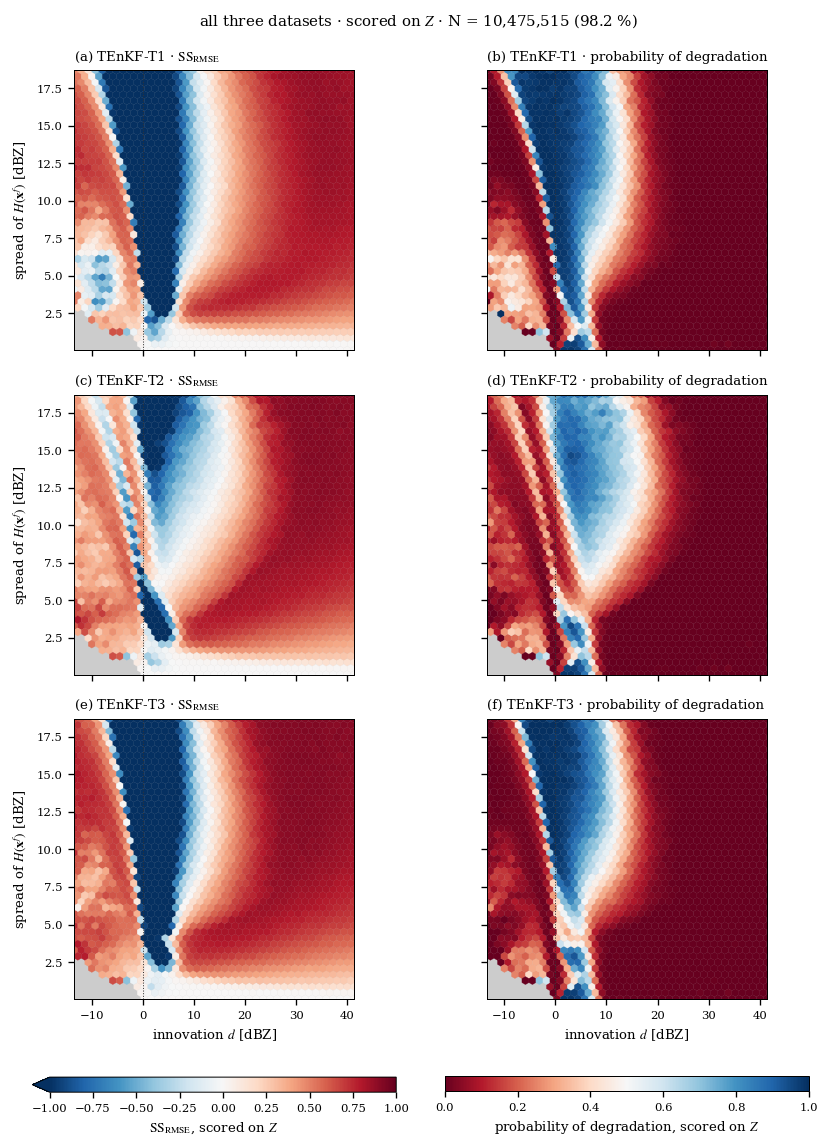

In [8]:
# Un ejemplo en línea: innovación × dispersión de H(x_f), los tres datasets juntos, evaluado en Z.
g_ex, S_ex = pair_sums("d", "Z_spread")
nb.save(lambda lang: draw_pair("d", "Z_spread", "obs", "pooled", S_ex, g_ex, lang),
        stem("obs", "pooled", "d", "Z_spread"), show=SHOW, langs=SAVE_LANGS)
plt.show()

## 3 · Todas las parejas

`PAIRS`: las parejas de `METRICS`, con la métrica que va primero en `METRICS` en el eje x. Por pareja, una figura por variable evaluada y por dataset (A, B, C, pooled).

In [9]:
PAIRS = list(itertools.combinations(METRICS, 2))
DS_FIGS = DATASETS + ("pooled",)
print(f"{len(PAIRS)} parejas × {len(SCORED)} variables evaluadas × {len(DS_FIGS)} = "
      f"{len(PAIRS) * len(SCORED) * len(DS_FIGS)} figuras, en {', '.join(SAVE_LANGS)}")

t0 = time.time()
for i, (mx, my) in enumerate(PAIRS):
    g, S = pair_sums(mx, my)
    for v in SCORED:
        for ds in DS_FIGS:
            with contextlib.redirect_stdout(io.StringIO()):     # nb.save imprime cada ruta
                nb.save(lambda lang: draw_pair(mx, my, v, ds, S, g, lang),
                        stem(v, ds, mx, my), show=False, langs=SAVE_LANGS)
    if (i + 1) % 6 == 0 or i + 1 == len(PAIRS):
        print(f"  {i + 1:2d}/{len(PAIRS)}  ({time.time() - t0:.0f} s)", flush=True)
print(f"en {nb.FIG_DIR.relative_to(nb.REPO)}/<idioma>/N5/<variable evaluada>/<dataset>/<x>__<y>.png")

78 parejas × 2 variables evaluadas × 4 = 624 figuras, en en
   6/78  (86 s)
  12/78  (184 s)
  18/78  (292 s)
  24/78  (427 s)
  30/78  (599 s)
  36/78  (794 s)
  42/78  (987 s)
  48/78  (1176 s)
  54/78  (1376 s)
  60/78  (1565 s)
  66/78  (1780 s)
  72/78  (1970 s)
  78/78  (2165 s)
en Notebooks/figures/<idioma>/N5/<variable evaluada>/<dataset>/<x>__<y>.png


## 4 · Las observaciones débiles

$\overline{H(\mathbf{x}^f)} \ge 0$, así que $d = y^o - \overline{H(\mathbf{x}^f)} \le y^o$ en todos los experimentos (se comprueba abajo): pedir $d < 10$ y $y^o < 10$ es lo mismo que pedir $y^o < 10$, y eso es cerca del 90 % de los experimentos. La observación lleva ruido gaussiano de varianza $R$ y se recorta en 0 dBZ: una verdad sin eco da $y^o = 0$ la mitad de las veces y $y^o$ entre 0 y unos $2{,}5\sqrt{R}$ la otra mitad.

Primera tabla, los tres datasets juntos, por tramo de $y^o$: la parte de los experimentos, la parte con verdad sin eco ($h(\mathbf{x}_\mathrm{true}) = 0$), el $\mathrm{SS}_\mathrm{RMSE}$ de $Z$ y de $w$ de T1, T2 y T3, y qué parte del exceso de $\sum e_a^2$ de $w$ de T2 sobre T1 cae en el tramo (suma 100 %; negativo: ahí T2 es mejor que T1). Segunda tabla, por dataset: $0 < y^o <$ `WEAK_HI` contra el resto, con cuántos de los 60 miembros verdad tienen $\mathrm{SS}_\mathrm{RMSE}$ de $w$ menor con T2 que con T1.

In [10]:
YO_EDGES = (0.0, 2.0, 4.0, 6.0, 10.0, 20.0, np.inf)
WEAK_HI = 6.0           # dBZ, unos 2,7 √R: por debajo, casi todo es ruido sobre una verdad sin eco
for ds in DATASETS:
    assert np.all(P[ds]["d"].astype(float) <= P[ds]["Z_obs"].astype(float) + 1e-4), f"{ds}: d > y^o"


def tramos(Q):
    yo = Q["Z_obs"]
    out = {"y^o = 0": yo == 0}
    for lo, hi in zip(YO_EDGES[:-1], YO_EDGES[1:]):
        out[f"({lo:g}, {hi:g})" if lo == 0 else f"[{lo:g}, {hi:g})"] = ((yo > lo) if lo == 0 else (yo >= lo)) & (yo < hi)
    return out


def se2(Q, m, v, n=None):
    """Σe² del prior (n None) o de T_n sobre los experimentos de m con error finito."""
    ef, ea = Q[f"ef_{v}"], Q[f"ea_{v}_T{n if n else NT[0]}"]
    ok = m & np.isfinite(ef) & np.isfinite(ea)
    return float(np.sum((ef if n is None else ea)[ok] ** 2))


def ss_truth(Q, m, v, n):
    """SS_RMSE de T_n por miembro verdad, con sus cuatro horas juntas."""
    ef, ea = Q[f"ef_{v}"], Q[f"ea_{v}_T{n}"]
    ok = m & np.isfinite(ef) & np.isfinite(ea)
    tm = Q["tm"][ok].astype(np.intp)
    return 1 - np.sqrt(np.bincount(tm, ea[ok] ** 2, len(TMS)) / np.bincount(tm, ef[ok] ** 2, len(TMS)))


KEEP = ("Z_obs", "Z_true", "tm") + tuple(f"e{s}_{v}{t}" for v in SCORED for s, t in
                                        [("f", "")] + [("a", f"_T{n}") for n in NT])
QP = {k: np.concatenate([P[ds][k] for ds in DATASETS]) for k in KEEP}
assert {"obs", "w"} <= set(SCORED)
excess = se2(QP, np.ones(QP["tm"].size, bool), "w", 2) - se2(QP, np.ones(QP["tm"].size, bool), "w", 1)
rows = {}
for name, m in tramos(QP).items():
    r = {"exp. [%]": 100 * m.mean(), "verdad sin eco [%]": 100 * np.mean(QP["Z_true"][m] <= 0)}
    for v, sv in (("obs", "Z"), ("w", "w")):
        for n in NT:
            r[f"SS {sv} T{n}"] = 1 - np.sqrt(se2(QP, m, v, n) / se2(QP, m, v))
    r["exceso w T2−T1 [%]"] = 100 * (se2(QP, m, "w", 2) - se2(QP, m, "w", 1)) / excess
    rows[name] = r
print("Los tres datasets juntos, por tramo de y^o [dBZ]")
print(pd.DataFrame(rows).T.to_string(float_format=lambda x: f"{x:.3f}"))

rows = []
for ds in DATASETS:
    Q = P[ds]
    weak = (Q["Z_obs"] > 0) & (Q["Z_obs"] < WEAK_HI)
    for name, m in ((f"0 < y^o < {WEAK_HI:g}", weak), ("resto", ~weak)):
        r = {"dataset": DSL[ds], "tramo": name, "exp. [%]": 100 * m.mean()}
        for v, sv in (("obs", "Z"), ("w", "w")):
            for n in NT:
                r[f"SS {sv} T{n}"] = 1 - np.sqrt(se2(Q, m, v, n) / se2(Q, m, v))
        r["SS w T2 < T1 (miembros)"] = int(np.sum(ss_truth(Q, m, "w", 2) < ss_truth(Q, m, "w", 1)))
        r["SS w T3 < T1 (miembros)"] = int(np.sum(ss_truth(Q, m, "w", 3) < ss_truth(Q, m, "w", 1)))
        rows.append(r)
print(f"\nPor dataset: 0 < y^o < {WEAK_HI:g} dBZ contra el resto (y^o = 0 incluido)")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.3f}"))
del QP

Los tres datasets juntos, por tramo de y^o [dBZ]
           exp. [%]  verdad sin eco [%]  SS Z T1  SS Z T2  SS Z T3  SS w T1  SS w T2  SS w T3  exceso w T2−T1 [%]
y^o = 0      43.929              99.348    0.630    0.720    0.750    0.037    0.016    0.009               6.444
(0, 2)       27.902              98.458   -0.636   -0.274   -0.028    0.036   -0.187   -0.205              49.358
[2, 4)       13.535              95.677   -2.459   -0.093   -1.768    0.007   -0.659   -0.437              92.992
[4, 6)        3.556              81.894   -2.992    0.002   -2.587   -0.037   -0.570   -0.269              24.790
[6, 10)       1.647              19.214   -1.405    0.024   -1.242   -0.044   -0.197   -0.075               6.145
[10, 20)      3.269               0.008   -0.075    0.157   -0.033   -0.148   -0.146   -0.049              -0.206
[20, inf)     6.161               0.000    0.673    0.657    0.722   -0.012    0.021    0.029             -79.524

Por dataset: 0 < y^o < 6 dBZ contra el

## 5 · Reglas candidatas

Tres reglas sobre la misma población (rechazan la observación si se cumple la condición):

- `ninguna`;
- `d[0,10]`: $0 \le d \le 10$ dBZ, la regla de N3;
- `d[0,10], y^o<10`: además $y^o < 10$ dBZ. Como $d \le y^o$, es $\{d \ge 0,\ y^o < 10\}$: una observación con eco débil por encima de la media del ensamble. Las innovaciones negativas (la observación ve menos eco que el ensamble, $y^o = 0$ incluido) no se tocan con ninguna de las dos reglas.

La única diferencia entre las dos reglas es la franja $\{0 \le d \le 10,\ y^o \ge 10\}$, que la segunda conserva. Primero se comprueba que `d[0,10]` reproduce `N3_sums_rule.csv`. Después, por dataset: retención, $F$ y $\mathrm{SS}_\mathrm{RMSE}$ de $Z$ y de $w$ sobre las retenidas (agrupado ± desviación entre los 60 miembros verdad), y lo mismo en las dos franjas que las reglas rechazan.

In [11]:
RULES5 = {"ninguna": None, "d[0,10]": (0.0, 10.0, None), "d[0,10], y^o<10": (0.0, 10.0, 10.0)}


def rejected(Q, rule):
    """La parte que la regla rechaza: lo ≤ d ≤ hi y, si la regla lo pide, y^o < yo_max."""
    if rule is None:
        return np.zeros(Q["d"].size, bool)
    lo, hi, yo_max = rule
    r = (Q["d"] >= lo) & (Q["d"] <= hi)
    return r if yo_max is None else r & (Q["Z_obs"] < yo_max)


def by_truth(Q, m, v, n):
    """Sumas de N3 por miembro verdad (cuatro horas juntas) sobre los experimentos de m."""
    return sums_by(Q[f"ef_{v}"][m], Q[f"ea_{v}_T{n}"][m], TOLS[v], Q["tm"][m].astype(np.intp), len(TMS))


def f_ss(s):
    """(F, SS_RMSE) de sumas con columnas SUMS."""
    with np.errstate(divide="ignore", invalid="ignore"):
        return s[..., 4] / s[..., 3], 1 - np.sqrt(s[..., 2] / s[..., 1])


# d[0,10] tiene que dar las sumas de N3 por (hora, miembro verdad)
rule_n3 = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_rule.csv", dtype={"hour": str}, float_precision="round_trip")
hours = np.array([int(h) for h in HOURS])
ng = len(HOURS) * len(TMS)
for ds in DATASETS:
    Q = P[ds]
    keep = ~rejected(Q, RULES5["d[0,10]"])
    g = (np.searchsorted(hours, Q["hour"]) * len(TMS) + Q["tm"])[keep]
    for v in ("obs", "w"):
        for n in NT:
            mine = sums_by(Q[f"ef_{v}"][keep], Q[f"ea_{v}_T{n}"][keep], TOLS[v], g, ng)
            b = rule_n3[(rule_n3.dataset == ds) & (rule_n3["var"] == v) & (rule_n3.method == "TEnKF")
                        & (rule_n3.ntemp == n) & (rule_n3.rule == "d[0,10]")]
            gb = np.array([HOURS.index(h) * len(TMS) + t for h, t in zip(b.hour, b.tm)])
            ref = b[SUMS].to_numpy(float)[np.argsort(gb)]
            assert np.array_equal(np.sort(gb), np.arange(ng))
            assert np.array_equal(mine[:, [0, 3, 4]], ref[:, [0, 3, 4]]), f"{ds} {v} T{n}: conteos ≠ N3"
            assert np.allclose(mine[:, 1:3], ref[:, 1:3], rtol=1e-12, atol=0), f"{ds} {v} T{n}: Σe² ≠ N3"
print("d[0,10] verificada contra N3_sums_rule (Z y w, T1–T3, por hora y miembro verdad)\n")


def table(masks, label):
    """Una fila por (dataset, máscara): % de experimentos, F y SS_RMSE ± desviación entre miembros."""
    rows = []
    for ds in DATASETS:
        Q = P[ds]
        for name, m in masks(Q).items():
            r = {"dataset": DSL[ds], label: name, "exp. [%]": 100 * m.mean()}
            for v, sv in (("obs", "Z"), ("w", "w")):
                for n in NT:
                    s = by_truth(Q, m, v, n)
                    ok = s[:, 0] >= 20                       # N_MIN_TRUTH de N3
                    (F, ss), (Ft, sst) = f_ss(s.sum(0)), f_ss(s[ok])
                    r[(sv, f"F T{n}")] = f"{F:.3f} ± {np.std(Ft, ddof=1):.3f}"
                    r[(sv, f"SS T{n}")] = f"{ss:.3f} ± {np.std(sst, ddof=1):.3f}"
            rows.append(r)
    return pd.DataFrame(rows)


T5 = table(lambda Q: {k: ~rejected(Q, r) for k, r in RULES5.items()}, "regla")
for sv in ("Z", "w"):
    cols = ["dataset", "regla", "exp. [%]"] + [c for c in T5.columns if isinstance(c, tuple) and c[0] == sv]
    print(f"Retenidas, evaluado en {sv}: agrupado ± desviación entre los 60 miembros verdad")
    print(T5[cols].rename(columns=lambda c: c[1] if isinstance(c, tuple) else c)
          .rename(columns={"exp. [%]": "retenidas [%]"}).to_string(index=False, float_format=lambda x: f"{x:.1f}"), "\n")

T5b = table(lambda Q: {"0≤d≤10, y^o<10 (ambas)": rejected(Q, RULES5["d[0,10], y^o<10"]),
                       "0≤d≤10, y^o≥10 (solo d[0,10])": rejected(Q, RULES5["d[0,10]"]) & (Q["Z_obs"] >= 10)},
            "franja rechazada")
for sv in ("Z", "w"):
    cols = ["dataset", "franja rechazada", "exp. [%]"] + [c for c in T5b.columns if isinstance(c, tuple) and c[0] == sv]
    print(f"Las franjas que las reglas rechazan, evaluado en {sv}")
    print(T5b[cols].rename(columns=lambda c: c[1] if isinstance(c, tuple) else c)
          .to_string(index=False, float_format=lambda x: f"{x:.1f}"), "\n")

# Diferencia pareada: SS_RMSE con d[0,10], y^o<10 menos SS_RMSE con d[0,10]; agrupada y cuántos de
# los 60 miembros verdad la tienen negativa (la regla nueva peor).
rows = []
for ds in DATASETS:
    Q = P[ds]
    k_old, k_new = ~rejected(Q, RULES5["d[0,10]"]), ~rejected(Q, RULES5["d[0,10], y^o<10"])
    r = {"dataset": DSL[ds]}
    for v, sv in (("obs", "Z"), ("w", "w")):
        for n in NT:
            so, sn = by_truth(Q, k_old, v, n), by_truth(Q, k_new, v, n)
            dt = f_ss(sn)[1] - f_ss(so)[1]
            r[f"{sv} T{n}"] = f"{f_ss(sn.sum(0))[1] - f_ss(so.sum(0))[1]:+.4f} ({int(np.sum(dt < 0))}/{len(TMS)})"
    rows.append(r)
print("ΔSS_RMSE (d[0,10], y^o<10 − d[0,10]), agrupado (miembros verdad con Δ < 0)")
print(pd.DataFrame(rows).to_string(index=False))

d[0,10] verificada contra N3_sums_rule (Z y w, T1–T3, por hora y miembro verdad)

Retenidas, evaluado en Z: agrupado ± desviación entre los 60 miembros verdad
   dataset           regla  retenidas [%]          F T1          SS T1          F T2         SS T2          F T3         SS T3
4 km–5 min         ninguna          100.0 0.744 ± 0.005  0.022 ± 0.114 0.844 ± 0.005 0.485 ± 0.042 0.817 ± 0.004 0.204 ± 0.089
4 km–5 min         d[0,10]           71.9 0.869 ± 0.004  0.329 ± 0.075 0.919 ± 0.003 0.536 ± 0.038 0.924 ± 0.002 0.459 ± 0.058
4 km–5 min d[0,10], y^o<10           73.3 0.860 ± 0.004  0.310 ± 0.073 0.910 ± 0.004 0.520 ± 0.038 0.915 ± 0.003 0.435 ± 0.057
  4 km–1 h         ninguna          100.0 0.782 ± 0.005 -0.170 ± 0.242 0.857 ± 0.004 0.449 ± 0.076 0.831 ± 0.004 0.080 ± 0.183
  4 km–1 h         d[0,10]           64.0 0.927 ± 0.004  0.316 ± 0.126 0.955 ± 0.003 0.530 ± 0.056 0.956 ± 0.003 0.443 ± 0.092
  4 km–1 h d[0,10], y^o<10           64.4 0.924 ± 0.004  0.304 ± 0.125 0.952 ± 

/home/jorge.gacitua/datosdemerzel/miniconda3/envs/intermediate_exp/lib/python3.8/site-packages/numpy/core/_asarray.py:102: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return array(a, dtype, copy=False, order=order)
/home/jorge.gacitua/datosdemerzel/miniconda3/envs/intermediate_exp/lib/python3.8/site-packages/numpy/core/_asarray.py:102: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return array(a, dtype, copy=False, order=order)


Las franjas que las reglas rechazan, evaluado en Z
   dataset              franja rechazada  exp. [%]          F T1          SS T1          F T2          SS T2          F T3          SS T3
4 km–5 min        0≤d≤10, y^o<10 (ambas)      26.7 0.406 ± 0.006 -4.391 ± 0.296 0.653 ± 0.009 -0.523 ± 0.054 0.534 ± 0.006 -3.356 ± 0.235
4 km–5 min 0≤d≤10, y^o≥10 (solo d[0,10])       1.4 0.429 ± 0.060 -0.497 ± 0.121 0.466 ± 0.053 -0.111 ± 0.047 0.506 ± 0.055 -0.466 ± 0.111
  4 km–1 h        0≤d≤10, y^o<10 (ambas)      35.6 0.511 ± 0.008 -4.558 ± 0.498 0.675 ± 0.007 -0.670 ± 0.124 0.597 ± 0.008 -3.266 ± 0.382
  4 km–1 h 0≤d≤10, y^o≥10 (solo d[0,10])       0.4 0.500 ± 0.083 -0.337 ± 0.168 0.531 ± 0.088  0.043 ± 0.112 0.604 ± 0.079 -0.248 ± 0.177
2 km–5 min        0≤d≤10, y^o<10 (ambas)      23.4 0.411 ± 0.004 -4.374 ± 0.263 0.654 ± 0.007 -0.512 ± 0.045 0.533 ± 0.005 -3.419 ± 0.206
2 km–5 min 0≤d≤10, y^o≥10 (solo d[0,10])       2.1 0.340 ± 0.047 -0.668 ± 0.082 0.377 ± 0.040 -0.314 ± 0.038 0.394 ± 0.04

/home/jorge.gacitua/datosdemerzel/miniconda3/envs/intermediate_exp/lib/python3.8/site-packages/numpy/core/_asarray.py:102: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return array(a, dtype, copy=False, order=order)
/home/jorge.gacitua/datosdemerzel/miniconda3/envs/intermediate_exp/lib/python3.8/site-packages/numpy/core/_asarray.py:102: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return array(a, dtype, copy=False, order=order)


ΔSS_RMSE (d[0,10], y^o<10 − d[0,10]), agrupado (miembros verdad con Δ < 0)
   dataset            Z T1            Z T2            Z T3            w T1            w T2            w T3
4 km–5 min -0.0189 (60/60) -0.0155 (60/60) -0.0241 (60/60) -0.0004 (40/60) -0.0014 (39/60) +0.0003 (29/60)
  4 km–1 h -0.0122 (60/60) -0.0093 (60/60) -0.0141 (60/60) -0.0009 (47/60) -0.0011 (34/60) -0.0001 (30/60)
2 km–5 min -0.0261 (60/60) -0.0218 (60/60) -0.0374 (60/60) -0.0018 (56/60) -0.0019 (53/60) -0.0004 (40/60)


## 6 · Miembros con eco e innovación

El cruce que no aparece en las parejas de hexbins: la innovación $d$ contra el número de miembros del prior con eco en la celda, $N_{Z>0}$ (`Z_nact`). Es discreto, así que va en tramos y no en hexágonos, y ninguna métrica de `METRICS` lo sustituye: con $N_{Z>0} = 1$ la asimetría y el exceso de curtosis de $H(\mathbf{x}^f)$ valen siempre lo mismo (un solo valor distinto de cero entre 59 da $\approx 7{,}29$ y $\approx 54{,}0$), así que todas esas observaciones caen sobre una sola columna en el borde del eje, y las de 2 a 6 miembros se mezclan entre sí. La primera tabla lo muestra; la segunda, la población y el $\mathrm{SS}_\mathrm{RMSE}$ por tramo de $d$ y de $N_{Z>0}$.

Las figuras son mapas de calor con las mismas definiciones que los hexbins ($\mathrm{SS}_\mathrm{RMSE}$ y $P_\mathrm{deg}$ sobre la población de cada casilla, los mismos colores) y una casilla gris si tiene menos de `N_MIN_CELL` experimentos. La figura de conteos muestra los experimentos por casilla, sin normalizar. Los tramos de $d$ tienen los bordes de la regla: $0 \le d \le 10$ son las columnas entre las dos líneas verticales.


In [12]:
DE = np.array([-np.inf, -10, -5, -2, -1, 0, 1, 2, 3, 4, 6, 8, 10, 15, 20, np.inf])
D_TICKS = ("<−10", "[−10, −5)", "[−5, −2)", "[−2, −1)", "[−1, 0)", "[0, 1)", "[1, 2)", "[2, 3)", "[3, 4)",
           "[4, 6)", "[6, 8)", "[8, 10]", "(10, 15)", "[15, 20)", "≥20")
NE = np.array([1, 2, 3, 5, 7, 11, 16, 31, 60])        # bordes inferiores de los tramos de N_{Z>0}
N_TICKS = ("1", "2", "3–4", "5–6", "7–10", "11–15", "16–30", "31–59")
BAND_COLS = (5, 11)                                   # primera y última columna de 0 ≤ d ≤ 10
N_MIN_CELL = 50
ND, NN = len(D_TICKS), len(N_TICKS)


def d_bin(d):
    """Tramo de d; d = 10 va con [8, 10], como en la regla (cerrada)."""
    d = np.asarray(d, float)
    return np.where(d == 10.0, 11, np.searchsorted(DE, d, side="right") - 1)


def n_bin(n):
    return np.searchsorted(NE, np.asarray(n), side="right") - 1


assert all(d_bin([lo])[0] == i for i, lo in enumerate(DE[1:-1], start=1) if lo != 10)   # 10 va con [8, 10]
assert d_bin([0.0])[0] == BAND_COLS[0] and d_bin([10.0])[0] == BAND_COLS[1] and d_bin([10.01])[0] == BAND_COLS[1] + 1

# Sumas de N3 por casilla (N_{Z>0}, d), por dataset y agrupadas; más el conteo de todos los experimentos.
GS, GCOUNT = {}, {}
for ds in DATASETS:
    Q = P[ds]
    g = n_bin(Q["Z_nact"]) * ND + d_bin(Q["d"])
    assert (n_bin(Q["Z_nact"]) >= 0).all()
    GCOUNT[ds] = np.bincount(g, minlength=NN * ND).reshape(NN, ND)
    for v in SCORED:
        for n in NT:
            GS[(ds, v, n)] = sums_by(Q[f"ef_{v}"], Q[f"ea_{v}_T{n}"], TOLS[v], g, NN * ND).reshape(NN, ND, -1)
GCOUNT["pooled"] = sum(GCOUNT[ds] for ds in DATASETS)
for v in SCORED:
    for n in NT:
        GS[("pooled", v, n)] = sum(GS[(ds, v, n)] for ds in DATASETS)


def grid_stats(s):
    """SS_RMSE y P_deg por casilla; NaN donde hay menos de N_MIN_CELL experimentos."""
    with np.errstate(divide="ignore", invalid="ignore"):
        ss = 1 - np.sqrt(s[..., 2] / s[..., 1])
        pdeg = 1 - s[..., 4] / s[..., 3]
    few = s[..., 0] < N_MIN_CELL
    return np.where(few, np.nan, ss), np.where(few | (s[..., 3] < N_MIN_CELL), np.nan, pdeg)


# Por qué los hexbins no lo muestran: Z_skew y Z_kurt por tramo de N_{Z>0}, los tres datasets juntos.
nact = np.concatenate([P[ds]["Z_nact"] for ds in DATASETS])
nb_ = n_bin(nact)
rows = []
for name in ("Z_skew", "Z_kurt"):
    x = np.concatenate([P[ds][name] for ds in DATASETS]).astype(float)
    hi = LIM[name][1]
    for i, t in enumerate(N_TICKS):
        m = nb_ == i
        rows.append({"métrica": name, "N_Z>0": t, "exp. [%]": 100 * m.mean(),
                     "mín": np.nanmin(x[m]), "mediana": np.nanmedian(x[m]), "máx": np.nanmax(x[m]),
                     "≥ lím. sup. − 0,01 [%]": 100 * np.mean(x[m] >= hi - 0.01)})
print(f"Asimetría y exceso de curtosis de H(x_f) por N_Z>0, los tres datasets juntos "
      f"(lím. sup. del eje: Z_skew {LIM['Z_skew'][1]:.3f}, Z_kurt {LIM['Z_kurt'][1]:.2f}; "
      f"ancho de un hexágono en d: {(LIM['d'][1] - LIM['d'][0]) / GRID_NX:.2f} dBZ)")
print(pd.DataFrame(rows).set_index(["métrica", "N_Z>0"]).to_string(float_format=lambda v: f"{v:.2f}"))
del nact, nb_, x

# Población y SS_RMSE por tramo de la regla y de N_{Z>0}, los tres datasets juntos.
TRAMO_COLS = {"d < 0": slice(0, BAND_COLS[0]), "0 ≤ d ≤ 10": slice(BAND_COLS[0], BAND_COLS[1] + 1),
              "d > 10": slice(BAND_COLS[1] + 1, ND)}
N_COARSE = {"1–2": slice(0, 2), "3–6": slice(2, 4), "7–15": slice(4, 6), "16–30": slice(6, 7), "31–59": slice(7, 8)}
rows = []
tot = GCOUNT["pooled"].sum()
for tr, cs in TRAMO_COLS.items():
    for nn, rs in N_COARSE.items():
        r = {"tramo": tr, "N_Z>0": nn, "exp. [%]": 100 * GCOUNT["pooled"][rs, cs].sum() / tot}
        for v, sv in (("obs", "Z"), ("w", "w")):
            for n in NT:
                s = GS[("pooled", v, n)][rs, cs].reshape(-1, 5).sum(0)
                r[f"SS {sv} T{n}"] = 1 - np.sqrt(s[2] / s[1])
        rows.append(r)
print("\nPor tramo de d y de N_Z>0, los tres datasets juntos: parte de los experimentos y SS_RMSE")
print(pd.DataFrame(rows).set_index(["tramo", "N_Z>0"]).to_string(float_format=lambda v: f"{v:.2f}"))


Asimetría y exceso de curtosis de H(x_f) por N_Z>0, los tres datasets juntos (lím. sup. del eje: Z_skew 7.295, Z_kurt 54.02; ancho de un hexágono en d: 1.37 dBZ)
               exp. [%]   mín  mediana   máx  ≥ lím. sup. − 0,01 [%]
métrica N_Z>0                                                       
Z_skew  1         20.66  7.29     7.29  7.30                  100.00
        2         12.76  5.02     5.91  7.30                    3.22
        3–4       16.30  3.35     4.78  7.29                    0.03
        5–6       10.97  2.58     3.77  7.26                    0.00
        7–10      15.56  1.80     2.95  7.10                    0.00
        11–15     11.22  1.25     2.20  7.04                    0.00
        16–30      9.60  0.21     1.50  5.97                    0.00
        31–59      2.93 -2.52     0.40  4.21                    0.00
Z_kurt  1         20.66 54.02    54.02 54.02                  100.00
        2         12.76 24.54    36.94 54.02                    0.98
        3–

figures/en/N5/grupos/conteos.png


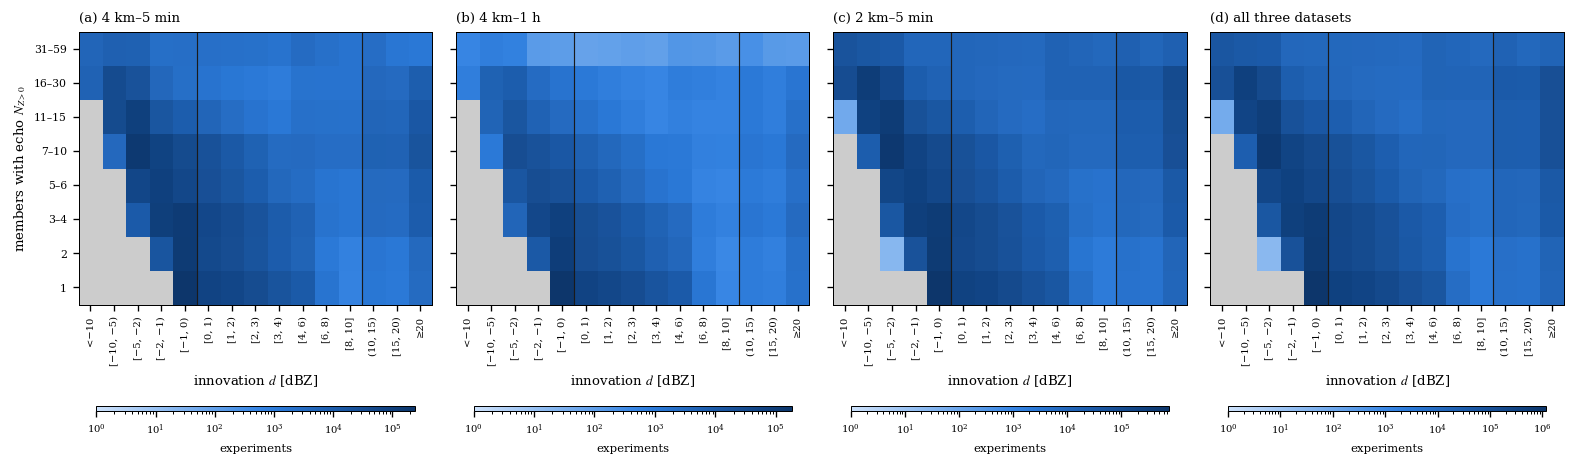

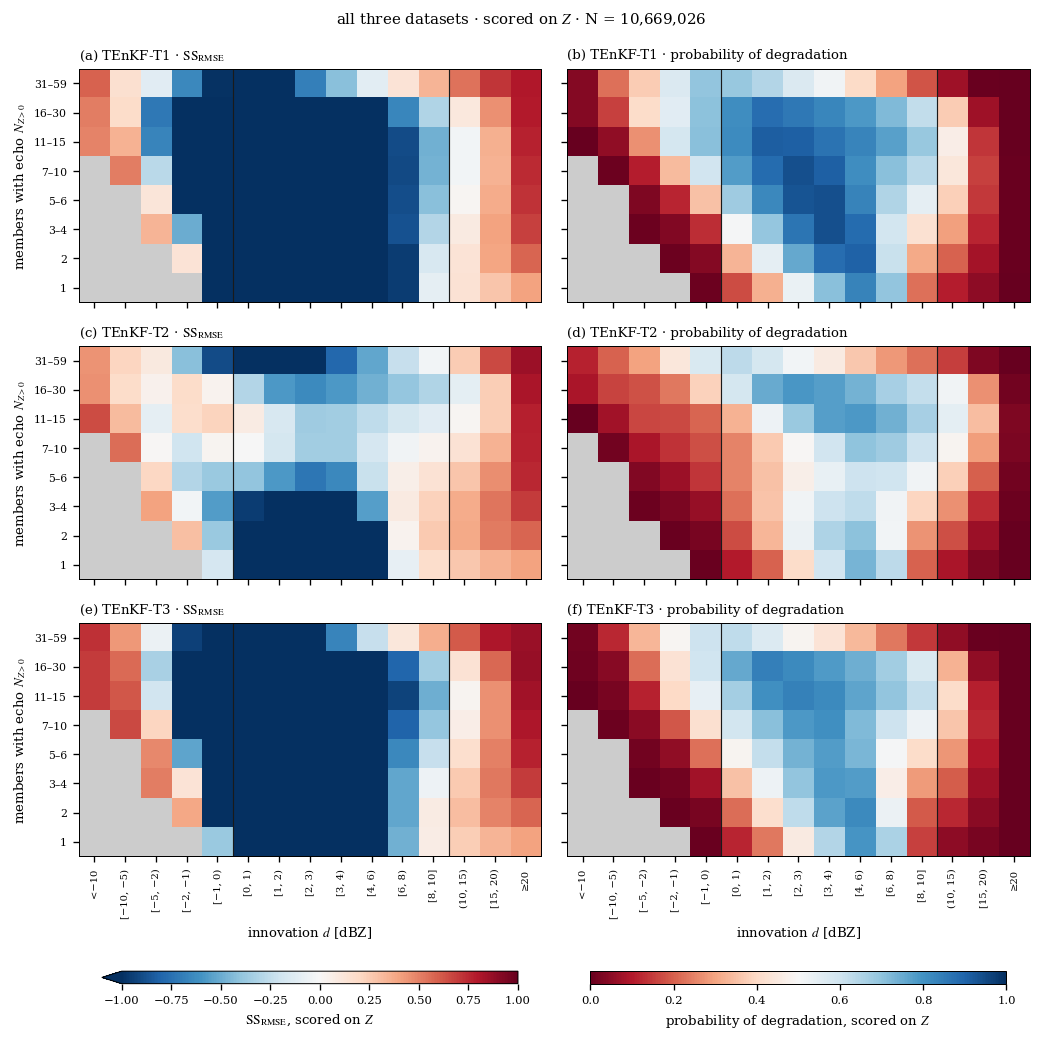

en Notebooks/figures/<idioma>/N5/grupos/


In [13]:
def heat(ax, A, cmap, norm):
    ax.set_facecolor(BG)
    ax.grid(False)
    im = ax.imshow(np.ma.masked_invalid(A), origin="lower", aspect="auto", cmap=cmap, norm=norm,
                   interpolation="nearest")
    for c in (BAND_COLS[0] - 0.5, BAND_COLS[1] + 0.5):
        ax.axvline(c, color="0.1", lw=0.7)
    ax.set_xticks(range(ND))
    ax.set_yticks(range(NN))
    ax.set_yticklabels(N_TICKS, fontsize=6.5)
    return im


def draw_groups(v, ds, lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, axes = plt.subplots(len(NT), 2, sharex=True, sharey=True,
                             figsize=(nb.PAGE_W * 1.25, nb.PAGE_W * 1.25), constrained_layout=True)
    letters = iter("abcdef")
    for r, n in enumerate(NT):
        ss, pdeg = grid_stats(GS[(ds, v, n)])
        for c, (val, cmap, norm, name) in enumerate(((ss, SS_CMAP, SS_NORM, V["ss_rmse"]),
                                                     (pdeg, PD_CMAP, PD_NORM, V["p_deg"]))):
            ax = axes[r, c]
            heat(ax, val, cmap, norm)
            ax.set_title(f"({next(letters)}) {lab(n)} · {name}", loc="left", fontsize=8)
        axes[r, 0].set_ylabel(L["Z_nact"], fontsize=8)
    for c in range(2):
        axes[-1, c].set_xticklabels(D_TICKS, rotation=90, fontsize=6)
        axes[-1, c].set_xlabel(L["d"], fontsize=8)
    scored = f"{L['scored']} ${SYM[v]}$"
    for c, (cmap, norm, name, ext) in enumerate(((SS_CMAP, SS_NORM, V["ss_rmse"], "min"),
                                                (PD_CMAP, PD_NORM, V["p_deg"], "neither"))):
        cb = fig.colorbar(ScalarMappable(norm, cmap), ax=axes[:, c], location="bottom", shrink=0.9, aspect=30, extend=ext)
        cb.set_label(f"{name}, {scored}", fontsize=8)
        cb.ax.tick_params(labelsize=7)
    where = L["pooled"] if ds == "pooled" else DSL[ds]
    fig.suptitle(f"{where} · {scored} · N = {nb.fmt(int(GCOUNT[ds].sum()), lang, ',d')}", fontsize=9)
    return fig


def draw_counts(lang):
    from matplotlib.colors import LogNorm
    L = LABELS[lang]
    keys = DATASETS + ("pooled",)
    fig, axes = plt.subplots(1, len(keys), sharey=True, figsize=(nb.PAGE_W * 1.9, nb.PAGE_W * 0.55),
                             constrained_layout=True)
    for ax, ds, l in zip(axes, keys, "abcd"):
        A = GCOUNT[ds].astype(float)
        im = heat(ax, np.where(A > 0, A, np.nan), nb.CMAP_SEQ, LogNorm(vmin=1, vmax=A.max()))
        ax.set_xticklabels(D_TICKS, rotation=90, fontsize=6)
        ax.set_xlabel(L["d"], fontsize=8)
        ax.set_title(f"({l}) {L['pooled'] if ds == 'pooled' else DSL[ds]}", loc="left", fontsize=8)
        cb = fig.colorbar(im, ax=ax, location="bottom", shrink=0.9, aspect=20)
        cb.set_label(L["count"], fontsize=7)
        cb.ax.tick_params(labelsize=6)
    axes[0].set_ylabel(L["Z_nact"], fontsize=8)
    return fig


nb.save(draw_counts, "N5/grupos/conteos", show=SHOW, langs=SAVE_LANGS)
plt.show()
for v in SCORED:
    for ds in DATASETS + ("pooled",):
        shown = v == "obs" and ds == "pooled"
        with contextlib.redirect_stdout(io.StringIO()):
            nb.save(lambda lang: draw_groups(v, ds, lang), f"N5/grupos/{'Z' if v == 'obs' else v}/{ds}",
                    show=SHOW if shown else False, langs=SAVE_LANGS)
        if shown:
            plt.show()
print(f"en {nb.FIG_DIR.relative_to(nb.REPO)}/<idioma>/N5/grupos/")
